# Benchmark Structure Prediction Methods

In [1]:
import collections
import itertools

import IPython.display as ipy_display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pingouin as pg
import seaborn as sns
from matplotlib.axes import Axes
from matplotlib.ticker import PercentFormatter
from scipy import stats
from sklearn.metrics import auc, precision_recall_curve, roc_auc_score

In [2]:
sequences = pd.read_csv('../data/interim/sequences_sample_1500.csv', index_col='index')
sequences['fold'] = sequences['fold'].astype(str)

## Antigen Specificity

In [3]:
def calculate_performance(pae_scores: pd.Series, labels: pd.Series) -> pd.Series:
    roc_auc = 1 - roc_auc_score(labels, pae_scores)
    roc_auc01 = 1 - roc_auc_score(labels, pae_scores, max_fpr=0.1)

    precision, recall, _ = precision_recall_curve(labels, pae_scores)
    pr_auc = auc(recall, precision)

    return pd.Series({'roc_auc': roc_auc, 'roc_auc_01': roc_auc01, 'pr_auc': pr_auc})


def format_metric_name(metric_name: str) -> str:
    return metric_name.upper().replace('_01', ' 0.1').replace('_', '-')

In [4]:
af3_confidence_scores = pd.read_csv('../data/processed/confidence_scores_af3_af3_tcrmodel2_1500.csv')
af3_confidence_scores['model'] = 'AlphaFold3'

In [5]:
af3_confidence_scores['top_rank'] = False
af3_confidence_scores.loc[af3_confidence_scores.groupby('name')['ranking_score'].idxmax(), 'top_rank'] = True

In [6]:
chai_confidence_scores = pd.read_csv('../data/interim/confidence_scores_chai_af3_tcrmodel2_1500.csv')
chai_confidence_scores['model'] = 'Chai-1'

In [7]:
chai_confidence_scores['top_rank'] = False
chai_confidence_scores.loc[chai_confidence_scores.groupby('name')['aggregate_score'].idxmax(), 'top_rank'] = True

In [8]:
af2_confidence_scores = pd.read_csv('../data/interim/confidence_scores_af2_af3_tcrmodel2_1500.csv')
af2_confidence_scores['model'] = 'AlphaFold2'

In [9]:
af2_confidence_scores['top_rank'] = False
af2_confidence_scores.loc[af2_confidence_scores.groupby('name')['ranking_confidence'].idxmax(), 'top_rank'] = True

In [10]:
confidence_scores = pd.concat([af3_confidence_scores, chai_confidence_scores, af2_confidence_scores]).reset_index(
    drop=True
)

In [ ]:
confidence_scores = confidence_scores.merge(sequences, how='left', left_on='name', right_index=True)

### Overall

In [12]:
metric_scores = confidence_scores.groupby('model').apply(
    lambda group: calculate_performance(group['cdr_pmhc_pae_score'], group['label']), include_groups=False
)

metric_scores_top_rank = (
    confidence_scores.query('top_rank')
    .groupby('model')
    .apply(lambda group: calculate_performance(group['cdr_pmhc_pae_score'], group['label']), include_groups=False)
)

print('All')
ipy_display.display(metric_scores)

print()

print('Top Ranked')
ipy_display.display(metric_scores_top_rank)

All


,roc_auc,roc_auc_01,pr_auc
model,,,
AlphaFold2,0.550454,0.507561,0.464959
AlphaFold3,0.600333,0.502604,0.449024
Chai-1,0.612470,0.509743,0.432002



Top Ranked


,roc_auc,roc_auc_01,pr_auc
model,,,
AlphaFold2,0.541732,0.499883,0.483179
AlphaFold3,0.601385,0.504019,0.448398
Chai-1,0.610668,0.510204,0.433369


### Bootstrap

In [13]:
NUM_SAMPLES = 25
SAMPLE_SIZE = 500

names = confidence_scores['name'].unique()
rng = np.random.default_rng(123)

samples_metric_scores = []
samples_metric_scores_top_rank = []
for sample_num in range(1, NUM_SAMPLES + 1):
    sample_names = rng.choice(names, SAMPLE_SIZE)

    sample = confidence_scores[confidence_scores['name'].isin(sample_names)]

    sample_metric_scores = (
        sample.groupby('model')
        .apply(lambda group: calculate_performance(group['cdr_pmhc_pae_score'], group['label']), include_groups=False)
        .reset_index()
    )
    sample_metric_scores['sample_num'] = sample_num

    samples_metric_scores.append(sample_metric_scores)

    sample_metric_scores_top_rank = (
        sample.query('top_rank')
        .groupby('model')
        .apply(lambda group: calculate_performance(group['cdr_pmhc_pae_score'], group['label']), include_groups=False)
        .reset_index()
    )

    sample_metric_scores_top_rank['sample_num'] = sample_num

    samples_metric_scores_top_rank.append(sample_metric_scores_top_rank)

samples_metric_scores = pd.concat(samples_metric_scores).reset_index(drop=True)
samples_metric_scores_top_rank = pd.concat(samples_metric_scores_top_rank).reset_index(drop=True)

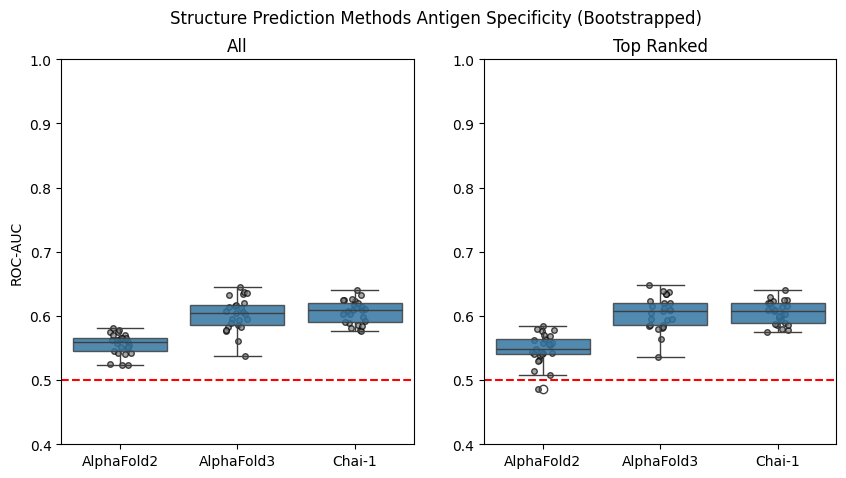

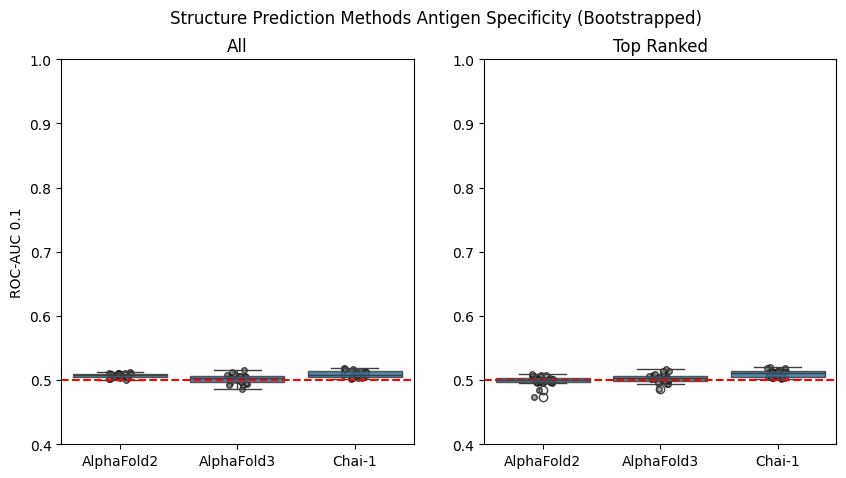

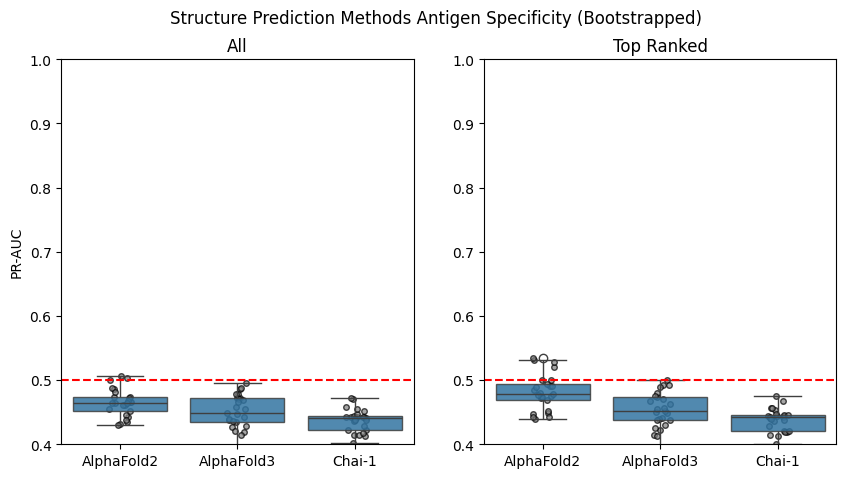

In [14]:
for metric_name in ('roc_auc', 'roc_auc_01', 'pr_auc'):
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))

    fig.suptitle('Structure Prediction Methods Antigen Specificity (Bootstrapped)')

    for i, (ax, title, data) in enumerate(
        zip(axes, ('All', 'Top Ranked'), (samples_metric_scores, samples_metric_scores_top_rank), strict=True)
    ):
        sns.stripplot(
            data,
            x='model',
            y=metric_name,
            color='grey',
            zorder=1,
            marker='o',
            size=4,
            edgecolor='black',
            linewidth=1,
            alpha=0.70,
            ax=ax,
        )
        sns.boxplot(data, x='model', y=metric_name, boxprops={'alpha': 0.85}, ax=ax)

        ax.axhline(0.5, color='r', linestyle='dashed')

        ax.set_title(title)
        ax.set_xlabel('')
        ax.set_ylim(0.4, 1.0)

        if i == 0:
            ax.set_ylabel(format_metric_name(metric_name))

        else:
            ax.set_ylabel('')

    plt.savefig(f'../report/figures/method_benchmark_specificity_bootstrap_{metric_name}.svg')
    plt.show()

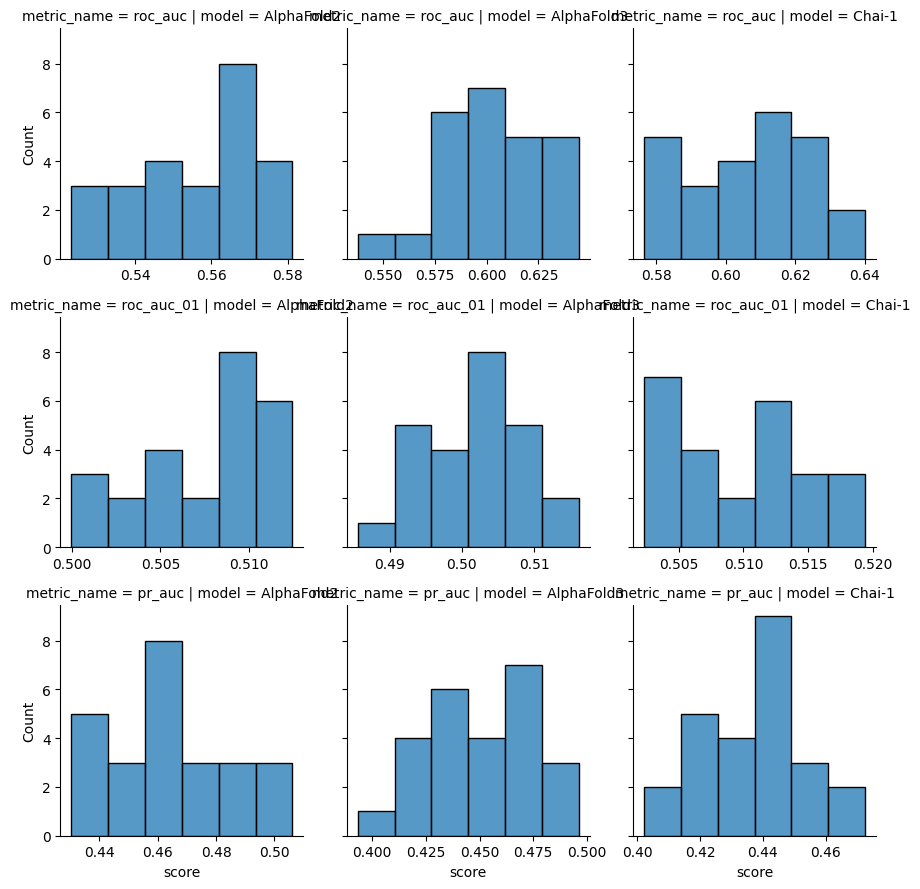

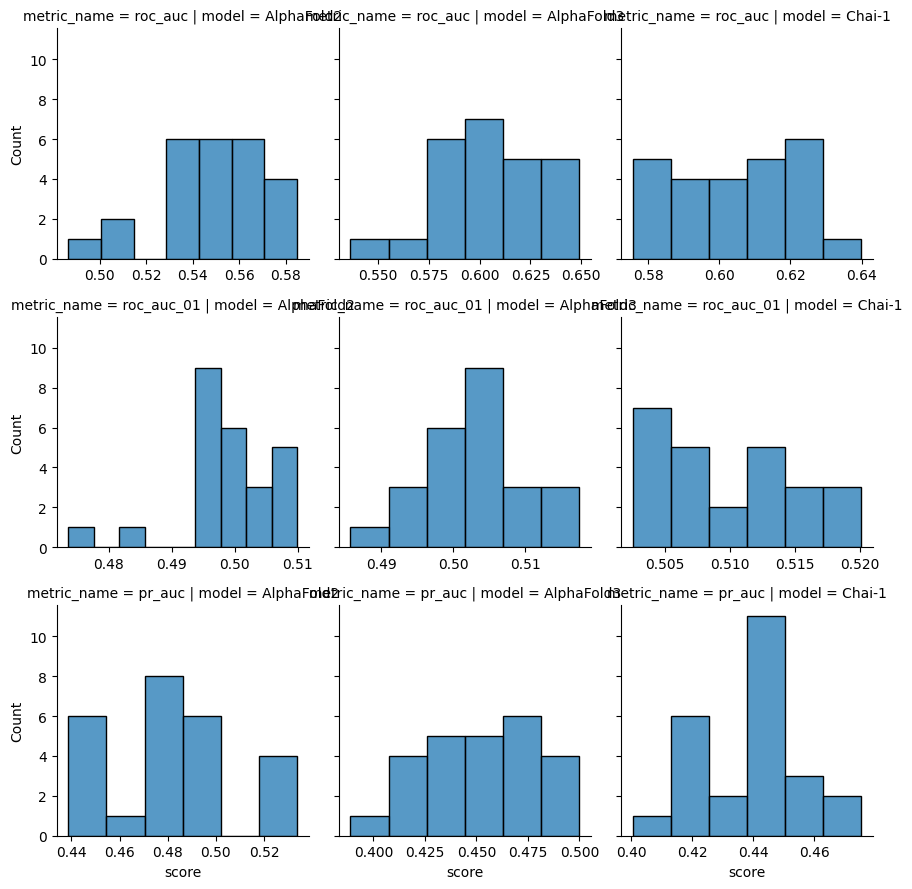

In [15]:
sns.FacetGrid(
    samples_metric_scores.melt(
        id_vars=['model', 'sample_num'],
        value_vars=['roc_auc', 'roc_auc_01', 'pr_auc'],
        var_name='metric_name',
        value_name='score',
    ),
    col='model',
    row='metric_name',
    sharex=False,
).map(sns.histplot, 'score')

sns.FacetGrid(
    samples_metric_scores_top_rank.melt(
        id_vars=['model', 'sample_num'],
        value_vars=['roc_auc', 'roc_auc_01', 'pr_auc'],
        var_name='metric_name',
        value_name='score',
    ),
    col='model',
    row='metric_name',
    sharex=False,
).map(sns.histplot, 'score')

plt.show()

In [16]:
def statistics_normal(data: pd.DataFrame, metric_name: str) -> tuple[pd.DataFrame, pd.DataFrame]:
    overall = pg.anova(data, dv=metric_name, between='model')

    groups = list(data.groupby('model')[metric_name])

    significance_level = 0.05 / len(groups)

    post_hoc = collections.defaultdict(list)
    for (group1_name, group1), (group2_name, group2) in itertools.combinations(groups, 2):
        stat, p_val = stats.ttest_ind(group1, group2, alternative='two-sided')

        post_hoc['group1'].append(group1_name)
        post_hoc['group2'].append(group2_name)
        post_hoc['stat'].append(stat)
        post_hoc['p_val'].append(p_val)
        post_hoc['signficant'].append(p_val < significance_level)

    return overall, pd.DataFrame(post_hoc)

In [17]:
for metric_name in ('roc_auc', 'roc_auc_01', 'pr_auc'):
    print(format_metric_name(metric_name))

    for title, data in zip(('All', 'Top Ranked'), (samples_metric_scores, samples_metric_scores_top_rank), strict=True):
        print(title)
        overall, post_hoc = statistics_normal(data, metric_name)

        ipy_display.display(overall)
        ipy_display.display(post_hoc)
        print()

ROC-AUC
All


,Source,ddof1,ddof2,F,p-unc,np2
0,model,2,72,46.745391,9.729997e-14,0.56493


,group1,group2,stat,p_val,signficant
0,AlphaFold2,AlphaFold3,-7.583583,9.430225e-10,True
1,AlphaFold2,Chai-1,-10.263852,1.072300e-13,True
2,AlphaFold3,Chai-1,-0.619773,5.383382e-01,False



Top Ranked


,Source,ddof1,ddof2,F,p-unc,np2
0,model,2,72,49.847647,2.586234e-14,0.580652


...

,Source,ddof1,ddof2,F,p-unc,np2
0,model,2,72,9.836268,0.000167,0.214596


,group1,group2,stat,p_val,signficant
0,AlphaFold2,AlphaFold3,2.037715,0.047111,False
1,AlphaFold2,Chai-1,4.991012,0.000008,True
2,AlphaFold3,Chai-1,2.189519,0.033453,False



Top Ranked


,Source,ddof1,ddof2,F,p-unc,np2
0,model,2,72,19.234112,2.029666e-07,0.348229


,group1,group2,stat,p_val,signficant
0,AlphaFold2,AlphaFold3,3.626016,6.949743e-04,True
1,AlphaFold2,Chai-1,6.544232,3.678562e-08,True
2,AlphaFold3,Chai-1,2.171603,3.485855e-02,False


### By Fold

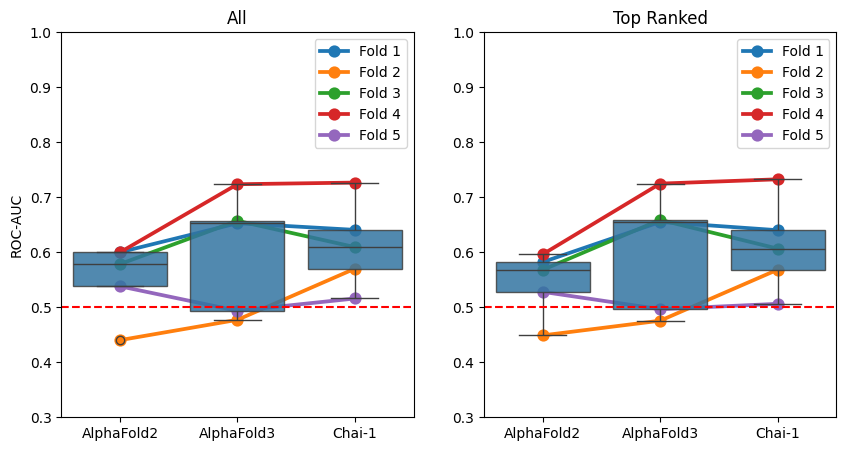

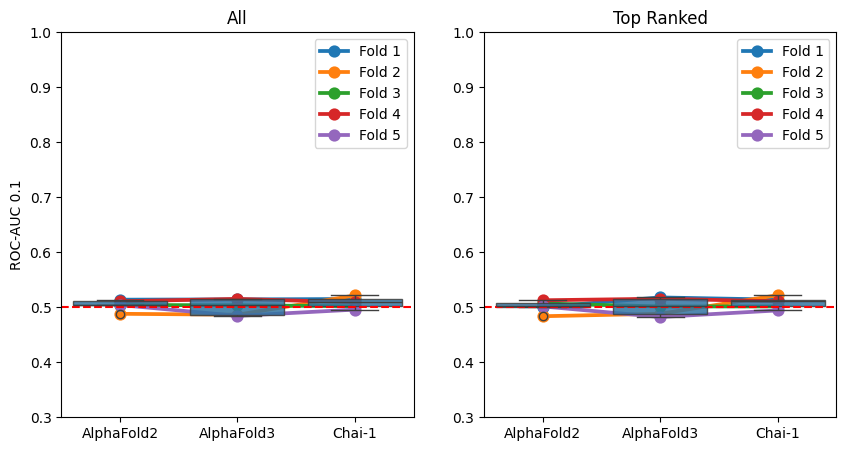

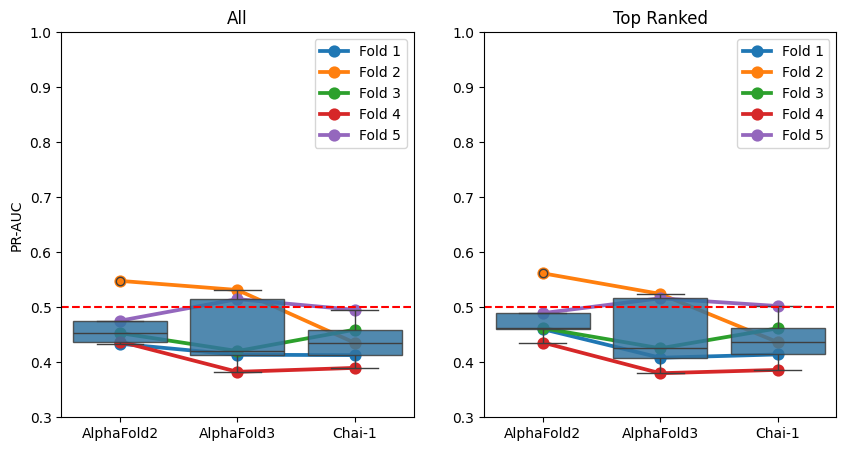

In [18]:
roc_aucs_by_fold = (
    confidence_scores.groupby(['model', 'fold'])
    .apply(lambda group: calculate_performance(group['cdr_pmhc_pae_score'], group['label']), include_groups=False)
    .reset_index()
)

roc_aucs_by_fold_top_rank = (
    confidence_scores.query('top_rank')
    .groupby(['model', 'fold'])
    .apply(lambda group: calculate_performance(group['cdr_pmhc_pae_score'], group['label']), include_groups=False)
    .reset_index()
)


for metric_name in ('roc_auc', 'roc_auc_01', 'pr_auc'):
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))

    for i, (ax, title, data) in enumerate(
        zip(axes, ('All', 'Top Ranked'), (roc_aucs_by_fold, roc_aucs_by_fold_top_rank), strict=True)
    ):
        sns.pointplot(data, x='model', y=metric_name, hue='fold', ax=ax)
        sns.boxplot(data, x='model', y=metric_name, boxprops={'alpha': 0.85}, ax=ax)

        ax.axhline(0.5, color='r', linestyle='dashed')

        ax.set_title(title)
        ax.set_xlabel('')
        ax.set_ylim(0.3, 1.0)

        handles, labels = ax.get_legend_handles_labels()
        new_labels = [f'Fold {label}' for label in labels]
        ax.legend(handles, new_labels)

        if i == 0:
            ax.set_ylabel(format_metric_name(metric_name))

        else:
            ax.set_ylabel('')

    plt.savefig(f'../report/figures/method_benchmark_specificity_fold_{metric_name}.svg')
    plt.show()

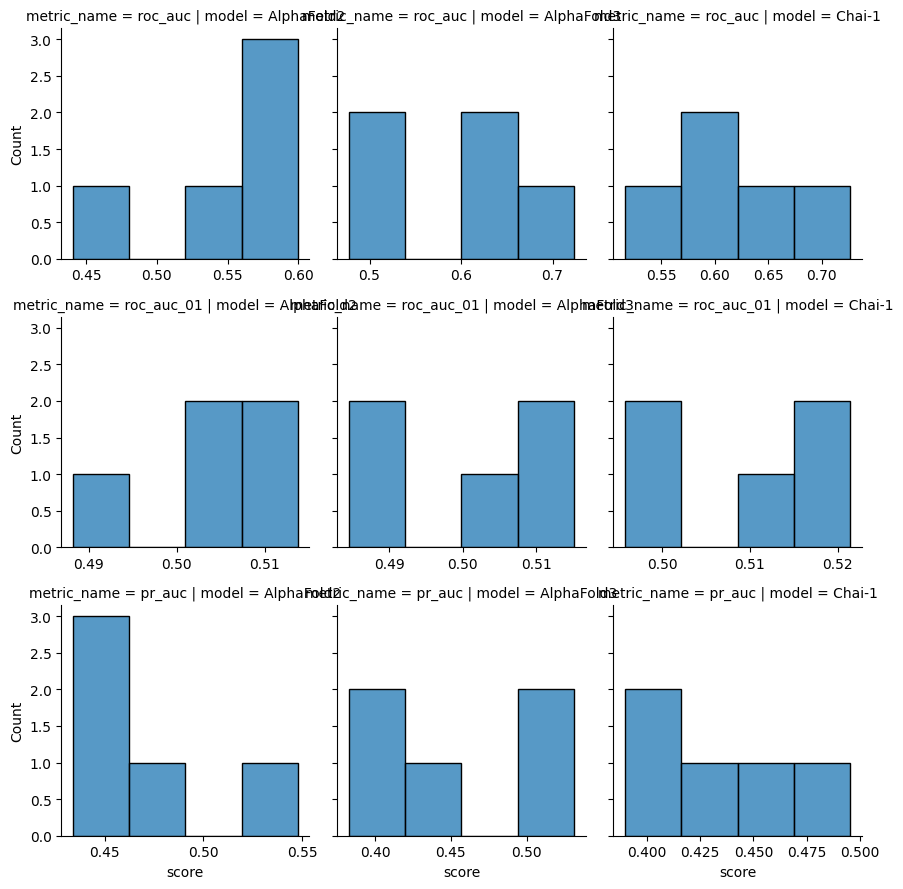

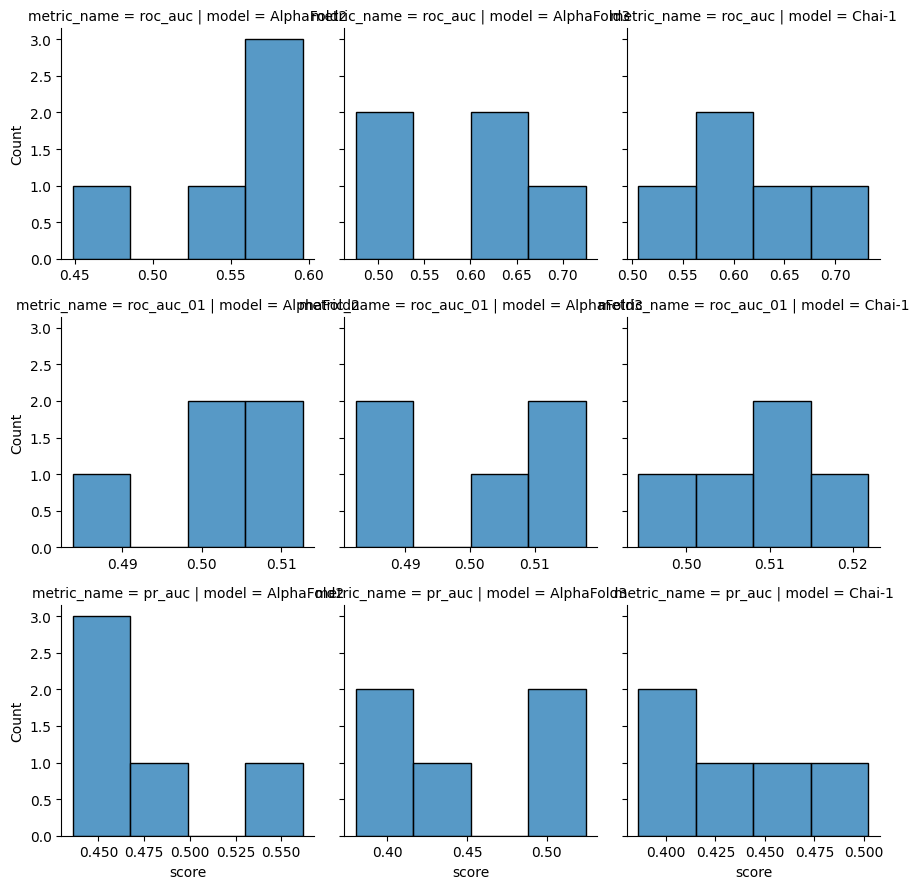

In [19]:
sns.FacetGrid(
    roc_aucs_by_fold.melt(
        id_vars=['model', 'fold'],
        value_vars=['roc_auc', 'roc_auc_01', 'pr_auc'],
        var_name='metric_name',
        value_name='score',
    ),
    col='model',
    row='metric_name',
    sharex=False,
).map(sns.histplot, 'score')

sns.FacetGrid(
    roc_aucs_by_fold_top_rank.melt(
        id_vars=['model', 'fold'],
        value_vars=['roc_auc', 'roc_auc_01', 'pr_auc'],
        var_name='metric_name',
        value_name='score',
    ),
    col='model',
    row='metric_name',
    sharex=False,
).map(sns.histplot, 'score')

plt.show()

In [20]:
def statistics_non_parametric(data: pd.DataFrame, metric_name: str) -> tuple[pd.DataFrame, pd.DataFrame]:
    overall = pg.friedman(data, dv=metric_name, within='model', subject='fold', method='f')

    groups = list(data.set_index('fold').groupby('model')[metric_name])
    groups = [(group_name, group.sort_index()) for group_name, group in groups]

    significance_level = 0.05 / len(groups)

    post_hoc = collections.defaultdict(list)
    for (group1_name, group1), (group2_name, group2) in itertools.combinations(groups, 2):
        stat, p_val = stats.wilcoxon(group1, group2, alternative='greater')

        post_hoc['group1'].append(group1_name)
        post_hoc['group2'].append(group2_name)
        post_hoc['stat'].append(stat)
        post_hoc['p_val'].append(p_val)
        post_hoc['signficant'].append(p_val < significance_level)

    return overall, pd.DataFrame(post_hoc)

In [21]:
for metric_name in ('roc_auc', 'roc_auc_01', 'pr_auc'):
    print(format_metric_name(metric_name))

    for title, data in zip(('All', 'Top Ranked'), (roc_aucs_by_fold, roc_aucs_by_fold_top_rank), strict=True):
        print(title)
        overall, post_hoc = statistics_non_parametric(data, metric_name)

        ipy_display.display(overall)
        ipy_display.display(post_hoc)

        print()

    print()

ROC-AUC
All


,Source,W,ddof1,ddof2,F,p-unc
Friedman,model,0.28,1.6,6.4,1.555556,0.274932


,group1,group2,stat,p_val,signficant
0,AlphaFold2,AlphaFold3,2.0,0.93750,False
1,AlphaFold2,Chai-1,1.0,0.96875,False
2,AlphaFold3,Chai-1,6.0,0.68750,False



Top Ranked


,Source,W,ddof1,ddof2,F,p-unc
Friedman,model,0.28,1.6,6.4,1.555556,0.274932


...

,Source,W,ddof1,ddof2,F,p-unc
Friedman,model,0.12,1.6,6.4,0.545455,0.567201


,group1,group2,stat,p_val,signficant
0,AlphaFold2,AlphaFold3,11.0,0.21875,False
1,AlphaFold2,Chai-1,12.0,0.15625,False
2,AlphaFold3,Chai-1,9.0,0.40625,False



Top Ranked


,Source,W,ddof1,ddof2,F,p-unc
Friedman,model,0.28,1.6,6.4,1.555556,0.274932


,group1,group2,stat,p_val,signficant
0,AlphaFold2,AlphaFold3,14.0,0.06250,False
1,AlphaFold2,Chai-1,13.0,0.09375,False
2,AlphaFold3,Chai-1,8.0,0.50000,False


## Structure Quality

In [22]:
af3_confidence_scores_benchmark = pd.read_csv('../data/interim/confidence_scores_af3_af3_tcrmodel2_benchmark.csv')

af3_confidence_scores_benchmark['top_rank'] = False
af3_confidence_scores_benchmark.loc[
    af3_confidence_scores_benchmark.groupby('name')['ranking_score'].idxmax(), 'top_rank'
] = True

af3_dockq_scores = pd.read_csv('../data/processed/predicted_af3_af3_tcrmodel2_dockq_benchmark.csv')
af3_dockq_scores['model'] = 'AlphaFold3'

af3_dockq_scores = af3_dockq_scores.merge(af3_confidence_scores_benchmark, how='inner', on=['name', 'seed', 'sample'])

In [23]:
chai_confidence_scores_benchmark = pd.read_csv('../data/interim/confidence_scores_chai_af3_tcrmodel2_benchmark.csv')

chai_confidence_scores_benchmark['top_rank'] = False
chai_confidence_scores_benchmark.loc[
    chai_confidence_scores_benchmark.groupby('name')['aggregate_score'].idxmax(), 'top_rank'
] = True

chai_dockq_scores = pd.read_csv('../data/processed/predicted_chai_af3_tcrmodel2_dockq_benchmark.csv')
chai_dockq_scores['model'] = 'Chai-1'

chai_dockq_scores = chai_dockq_scores.merge(
    chai_confidence_scores_benchmark, how='inner', on=['name', 'seed', 'sample']
)

In [24]:
af2_confidence_scores_benchmark = pd.read_csv('../data/interim/confidence_scores_af2_af3_tcrmodel2_benchmark.csv')

af2_confidence_scores_benchmark['top_rank'] = False
af2_confidence_scores_benchmark.loc[
    af2_confidence_scores_benchmark.groupby('name')['ranking_confidence'].idxmax(), 'top_rank'
] = True

af2_dockq_scores = pd.read_csv('../data/processed/predicted_af2_af3_tcrmodel2_dockq_benchmark.csv')
af2_dockq_scores['model'] = 'AlphaFold2'

af2_dockq_scores = af2_dockq_scores.merge(af2_confidence_scores_benchmark, how='inner', on=['name', 'seed', 'sample'])

In [25]:
dockq_scores = pd.concat([af3_dockq_scores, chai_dockq_scores, af2_dockq_scores])

In [26]:
dockq_scores.loc[dockq_scores['DockQ'].isna(), 'DockQ'] = 0.0

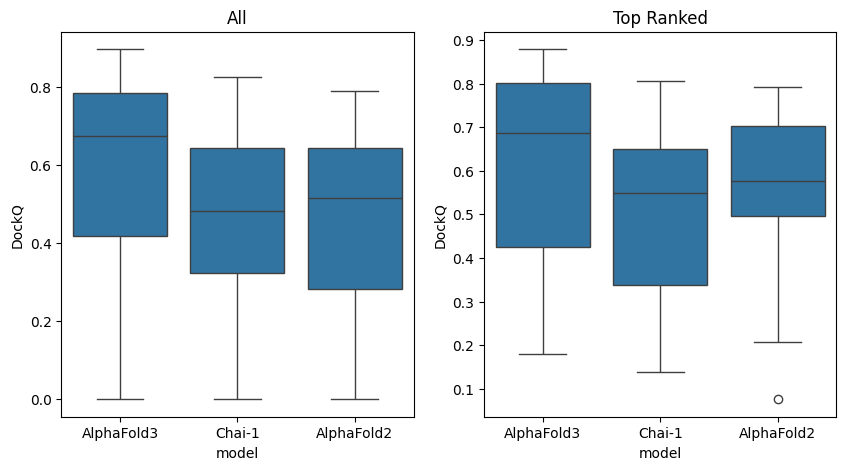

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

for ax, title, data in zip(axes, ('All', 'Top Ranked'), (dockq_scores, dockq_scores.query('top_rank')), strict=True):
    ax.set_title(title)

    sns.boxplot(data, x='model', y='DockQ', ax=ax)

plt.savefig('../report/figures/method_benchmark_dockq_boxplot.svg')
plt.show()

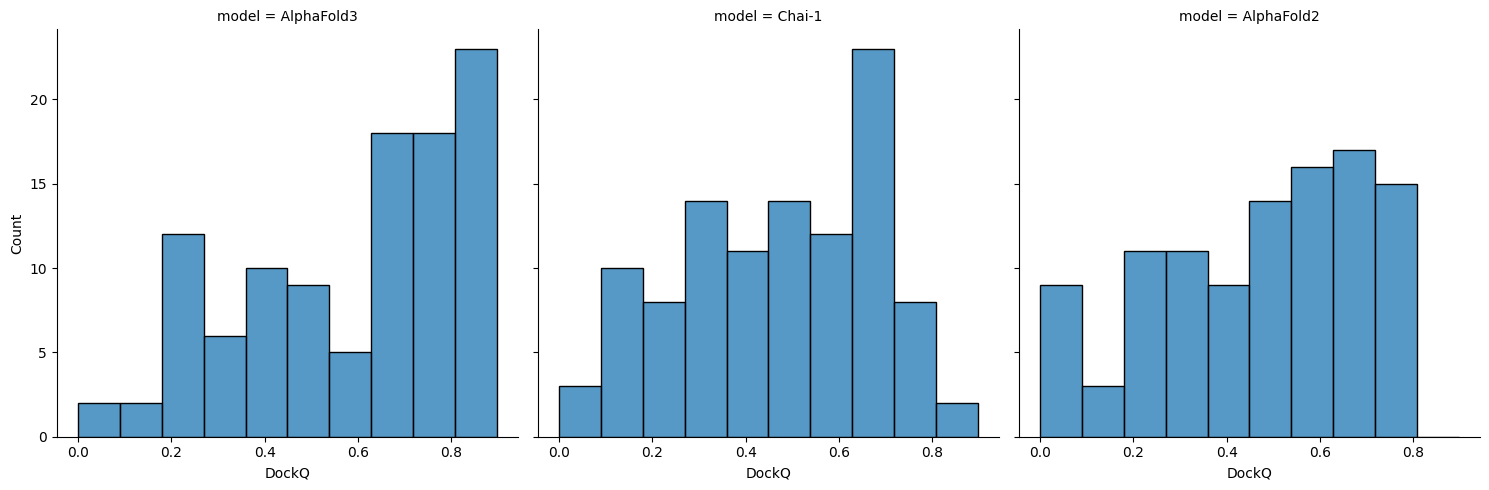

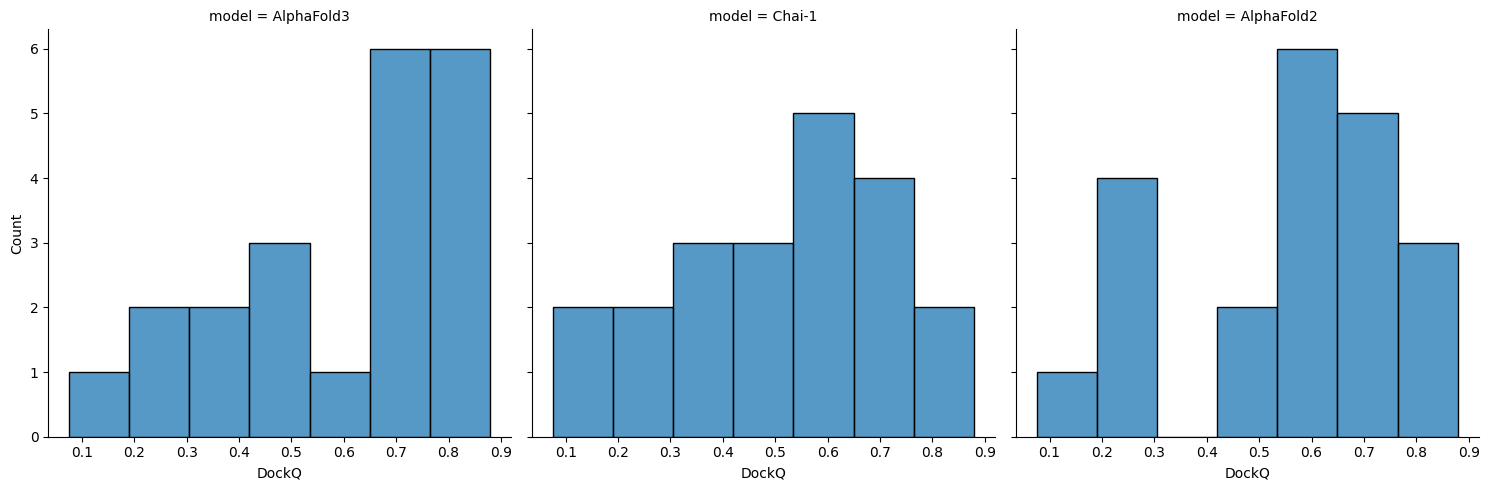

In [28]:
sns.displot(dockq_scores, col='model', x='DockQ', kind='hist')
sns.displot(dockq_scores.query('top_rank'), col='model', x='DockQ', kind='hist')

In [29]:
for title, data in zip(('All', 'Top Ranked'), (dockq_scores, dockq_scores.query('top_rank')), strict=True):
    print(title)

    ipy_display.display(pg.anova(data, dv='DockQ', between='model'))

    groups = list(data.groupby('model')['DockQ'])

    significance_level = 0.05 / len(groups)

    results = collections.defaultdict(list)
    for (group1_name, group1), (group2_name, group2) in itertools.combinations(groups, 2):
        stat, p_val = stats.ttest_ind(group1, group2, alternative='two-sided')

        results['group1'].append(group1_name)
        results['group2'].append(group2_name)
        results['stat'].append(stat)
        results['p_val'].append(p_val)
        results['signficant'].append(p_val < significance_level)

    ipy_display.display(pd.DataFrame(results))
    print()

All


,Source,ddof1,ddof2,F,p-unc,np2
0,model,2,312,10.579443,0.000036,0.06351


,group1,group2,stat,p_val,signficant
0,AlphaFold2,AlphaFold3,-3.775482,0.000208,True
1,AlphaFold2,Chai-1,0.197463,0.843658,False
2,AlphaFold3,Chai-1,4.039339,0.000075,True



Top Ranked


,Source,ddof1,ddof2,F,p-unc,np2
0,model,2,60,1.085522,0.344265,0.03492


,group1,group2,stat,p_val,signficant
0,AlphaFold2,AlphaFold3,-0.825443,0.414016,False
1,AlphaFold2,Chai-1,0.646581,0.521596,False
2,AlphaFold3,Chai-1,1.446921,0.155711,False


In [30]:
CAPRI_ACCEPTABLE_CUTOFF = 0.23
CAPRI_MEDIUM_CUTOFF = 0.49
CAPRI_HIGH_CUTOFF = 0.80


def get_capri_classification(dockq: float) -> str:
    if dockq < CAPRI_ACCEPTABLE_CUTOFF:
        return 'Incorrect'

    if CAPRI_ACCEPTABLE_CUTOFF <= dockq < CAPRI_MEDIUM_CUTOFF:
        return 'Acceptable'

    if CAPRI_MEDIUM_CUTOFF <= dockq < CAPRI_HIGH_CUTOFF:
        return 'Medium'

    return 'High'

In [31]:
dockq_scores['capri_classification'] = dockq_scores['DockQ'].map(get_capri_classification)

In [32]:
def plot_capri_classification(dockq_scores: pd.DataFrame, ax: Axes | None = None) -> Axes:
    capri_classification = dockq_scores.groupby('model')['capri_classification'].value_counts(normalize=True) * 100
    capri_classification.name = 'percent'
    capri_classification = capri_classification.reset_index()
    capri_classification = capri_classification.pivot_table(
        index='model', columns='capri_classification', values='percent'
    )

    order = ['High', 'Medium', 'Acceptable', 'Incorrect']
    colours = {
        'High': '#7f0d0d',
        'Medium': '#ff1a1a',
        'Acceptable': '#ff7f7f',
        'Incorrect': '#e6e6e6',
    }

    plot_ax = capri_classification.reindex(columns=order, fill_value=0).plot(
        kind='bar',
        stacked=True,
        color=[colours[col_name] for col_name in order],
        width=0.8,
        edgecolor='none',
        legend=False,
        ax=ax,
    )

    plot_ax.set_ylim(0, 100)
    plot_ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
    plot_ax.set_ylabel('Success rate', fontsize=12)
    plot_ax.set_yticks([0, 25, 50, 75, 100])
    plot_ax.set_xlabel('')

    return plot_ax

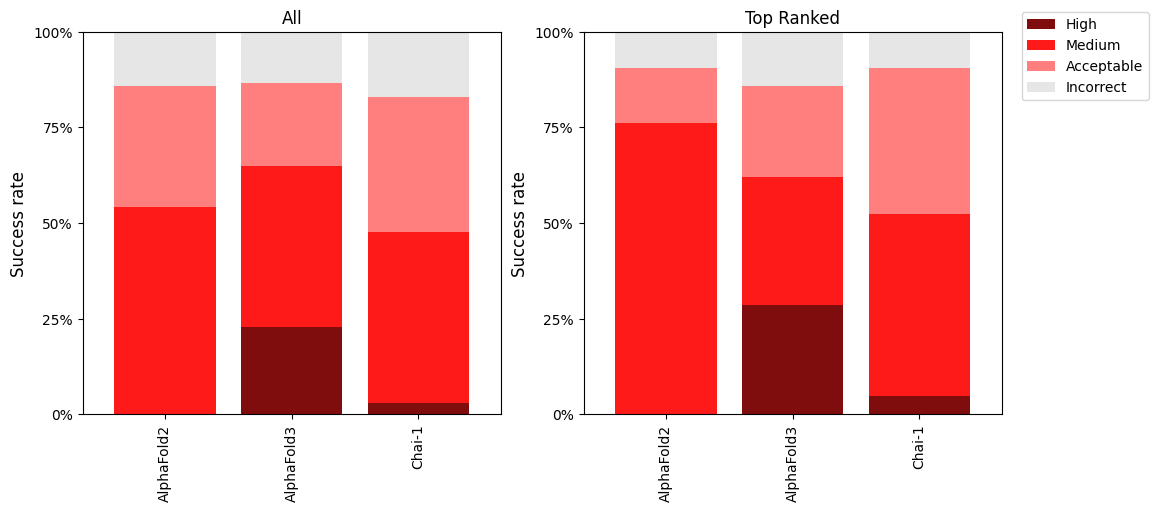

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5), constrained_layout=True)

for ax, title, data in zip(axes, ('All', 'Top Ranked'), (dockq_scores, dockq_scores.query('top_rank')), strict=True):
    ax.set_title(title)
    plot_capri_classification(data, ax=ax)


handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, bbox_to_anchor=(1.15, 1))

plt.savefig('../report/figures/method_benchmark_dockq_capri.svg', bbox_inches='tight')
plt.show()